In [1]:
        ########################### Deep Neural Networks Regression-Kriging using PyTorch and PyKrige #############################

In [75]:
# If you receive the message "The kernel ... appears to have died. It will restart automatically."
# OpenMP Runtime Conflict: If you see the crash during imports like Scikit-Learn or PyTorch, set this environment variable at the very top of your notebook:
# Type the following codes

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [76]:
########## 1. Installing and Importing libraries
# conda install conda-forge:: or pip install pykrige, pytorch, scikit-learn, numpy, and pandas
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from pykrige.rk import Krige
from pykrige.uk import UniversalKriging
from sklearn.preprocessing import StandardScaler # Scaling the input features
#from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import skgstat as skg
import torch
import torch.nn as nn
import torch.optim as optim
#from pykrige.ok import OrdinaryKriging
import matplotlib.pyplot as plt

In [77]:
# 1. Loading the dataset
data = pd.read_csv('E:/VData/SData/Wells4.csv')

In [78]:
seed = 42

In [79]:
data.head()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
0,17.74,15.57,259.0,7.00,39.0,9.0,27.0
1,17.48,15.82,220.0,6.60,17.0,12.0,34.7
2,17.48,15.83,220.0,6.00,925.0,5.0,27.0
3,17.39,15.37,286.0,7.00,3300.0,1.0,29.0
4,17.35,13.80,47.0,7.45,13.0,0.2,26.5


In [80]:
data.describe()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
count,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000
mean,15.499214,13.761732,49.371823,7.047918,49.873158,6.258383,28.451777
std,0.536874,0.508679,19.132128,0.618476,146.064968,15.023649,2.827740
min,13.930000,12.270000,15.400000,4.000000,0.000000,0.000000,10.000000
25%,15.230000,13.440000,38.000000,6.730000,9.000000,1.300000,27.000000
50%,15.480000,13.780000,48.000000,7.000000,18.000000,2.800000,29.000000
75%,15.730000,14.125000,56.000000,7.375000,35.000000,7.000000,30.000000
max,17.740000,15.830000,286.000000,10.800000,3300.000000,278.000000,35.100000


In [9]:
# 2. data preparation

In [81]:
# a. The predictor variables
p = []
p.append(data['T'])
p.append(data['Depth'])
p = np.array(p).T

In [82]:
p.shape

(1311, 2)

In [83]:
# b. Scaling the input features
# Initializing and fitting the scaler
scaler = StandardScaler()
scaler.fit(p)
StandardScaler()
# Scaling p
p = scaler.transform(p)

In [84]:
# c. The target
y1 = data['pH']

In [85]:
# d. Coordinates
u = data['x_coord'].values
v = data['y_coord'].values
coords = np.array(list(zip(u, v))) 

In [86]:
# e. Scaling the coords
# Initializing and fitting the coordinate scaler
scaler = StandardScaler()
scaler.fit(coords)
StandardScaler()
# Scaling coords
coords = scaler.transform(coords)

In [87]:
                            ################# DNN + Kriging #################################

In [88]:
############# 1. Creating a 2D Grid
x = np.linspace(0, 10, 50)
y = np.linspace(0, 10, 50)
X, Y = np.meshgrid(x, y)

In [89]:
############# 2. Defining a "True" surface: Trend (Sine) + Local Spatial Variation
# a. Trend: Depends on X and Y coordinates
trend = np.sin(u/2) * np.cos(v/2)
# b. Residuals: Artificial spatial clusters
residuals_true = 0.5 * np.exp(-((u-5)**2 + (v-5)**2)/2) 
z_true = trend + residuals_true

In [90]:
############ 3. Sampling 100 random points from this surface
sample_coords = coords 

In [91]:
sample_z = z_true 

In [22]:
############# 4. Training the Deep Neural Network (The Trend)
# We feed the coordinates (x,y) into the DNN to learn the global trend.


In [92]:
# a. Converting X and y training data  into Tensors
X_train = torch.tensor(coords, dtype = torch.float32)
y_train = torch.tensor(y1, dtype = torch.float32).view(-1, 1)

In [93]:
# b.Defining the Model
model = nn.Sequential(
    nn.Linear(2, 32),
    nn.ReLU(),
    nn.Linear(32, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
optimizer = optim.RMSprop(model.parameters(), lr = 0.06)
criterion = nn.MSELoss()

In [94]:
# c. Training the model
for epoch in range(500):
    optimizer.zero_grad()
    pred = model(X_train)
    loss = criterion(pred, y_train)
    loss.backward()
    optimizer.step()

In [96]:
# d. Getting the DNN Trend predictions for the whole grid
full_grid_coords = np.column_stack((X.ravel(), Y.ravel()))
with torch.no_grad():
    dnn_trend = model(torch.tensor(full_grid_coords, dtype = torch.float32)).numpy().reshape(50, 50)

In [97]:
############## 5. Kriging the Residuals
# Calculating the difference between the actual samples and what the DNN predicted.

In [98]:
# a. Calculating the residuals at sample locations
with torch.no_grad():
    sample_preds = model(X_train).numpy().flatten()
residuals = y1 - sample_preds


In [99]:
# b. Fitting Kriging model to the residuals
UK = UniversalKriging(
    coords[:, 0], 
    coords[:, 1], 
    residuals,
    variogram_model ='gaussian',
    verbose = False,
    enable_plotting = False
)

In [100]:
# c. Interpolating residuals across the full grid
z_res, ss_res = UK.execute('grid', x, y)

In [31]:
############ 6. Final Prediction and Visualization
# The final result is the DNN Trend + Kriged Residuals.

In [101]:
# a. Final Hybrid Prediction
y_final = dnn_trend + z_res

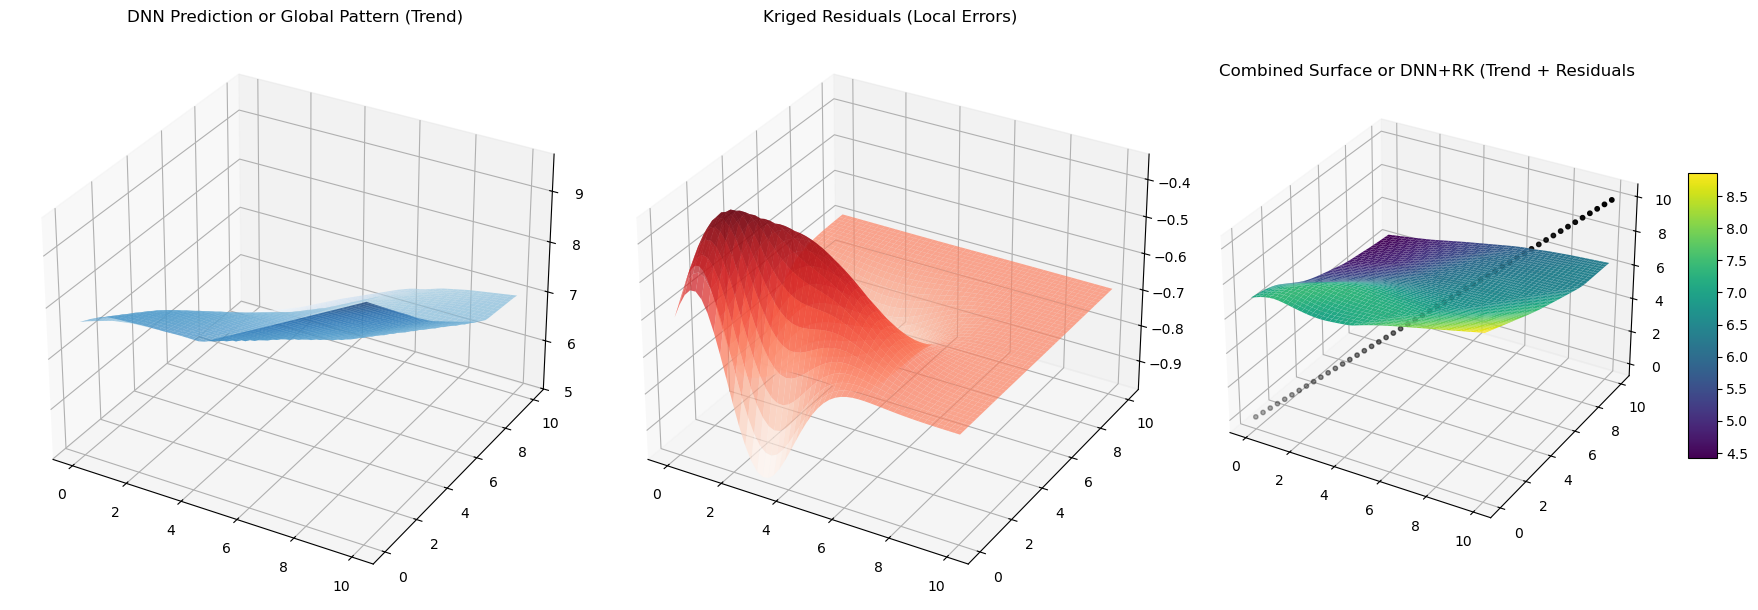

In [102]:
# b. PLotting the prediction (Trend), the kriged residuals, and the DNN-Regression Kriging (Trend + Residuals)
fig = plt.figure(figsize = (18, 6))

# Subplot 1: DNN Trend (Global)
ax1 = fig.add_subplot(131, projection = '3d')
ax1.plot_surface(X, Y, dnn_trend, cmap = 'Blues', alpha = 0.7)
ax1.set_title('DNN Prediction or Global Pattern (Trend)')

# Subplot 2: Kriged Residuals (Local)
ax2 = fig.add_subplot(132, projection='3d')
ax2.plot_surface(X, Y, z_res, cmap = 'Reds', alpha = 0.7)
ax2.set_title('Kriged Residuals (Local Errors)')

# Subplot 3: Final Combined Surface
ax3 = fig.add_subplot(133, projection = '3d')
surf = ax3.plot_surface(X, Y, y_final, cmap = 'viridis', antialiased = True)
ax3.scatter(x, y, y, color = 'black', s = 10, label = 'Actual Data')
ax3.set_title('Combined Surface or DNN+RK (Trend + Residuals')

fig.colorbar(surf, ax = ax3, shrink = 0.5, aspect = 10)
plt.tight_layout()
plt.show()


In [35]:
############# 7. Calculating and Plotting the Variogram

In [103]:
# a. Creating the Variogram Object ---
# n_lags: number of distance 'bins' to group point pairs
# maxlag: maximum distance to consider (usually 50% of the max distance in data)
V = skg.Variogram(coords, residuals, n_lags = 15, model = 'gaussian', normalize = False)

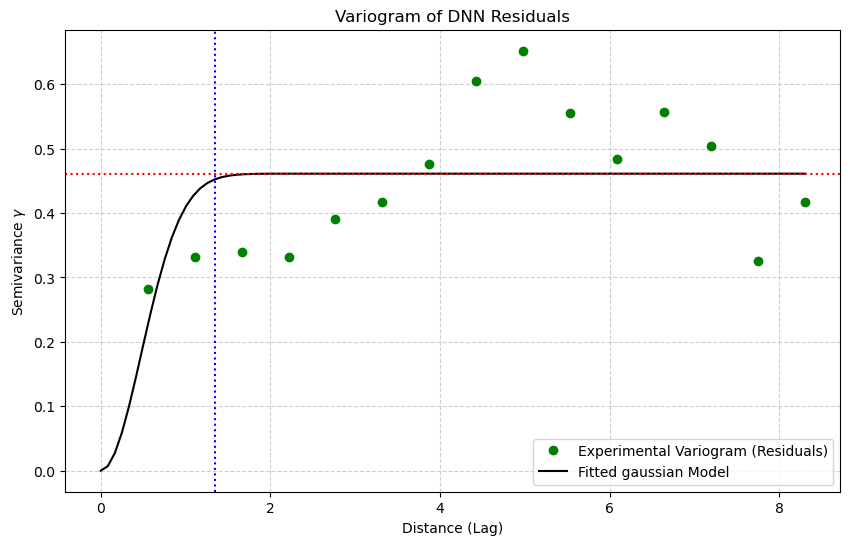

In [104]:
# b. Plotting the Experimental Variogram ---
plt.figure(figsize = (10, 6))

# Plot the experimental points (the dots)
plt.plot(V.bins, V.experimental, 'og', label = 'Experimental Variogram (Residuals)')

# Plot the fitted model (the line)
x_model = np.linspace(0, np.max(V.bins), 100)
y_model = V.fitted_model(x_model)
plt.plot(x_model, y_model, '-k', label = f'Fitted {V.model.__name__} Model')

# Formatting
plt.xlabel('Distance (Lag)')
plt.ylabel('Semivariance $\gamma$')
plt.title('Variogram of DNN Residuals')
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.6)

# Adding annotations for Kriging parameters
plt.axhline(y = V.parameters[1] + V.parameters[2], color = 'r', linestyle = ':', label = 'Sill')
plt.axvline(x = V.parameters[0], color = 'b', linestyle = ':', label = 'Range')

plt.show()

In [105]:
# Print the Geostatistical parameters
print(f"Range (Distance where correlation stops): {V.parameters[0]:.2f}")
print(f"Sill (Total Variance): {V.parameters[1] + V.parameters[2]:.2f}")
print(f"Nugget (Measurement Error/Micro-scale variation): {V.parameters[2]:.2f}")

Range (Distance where correlation stops): 1.35
Sill (Total Variance): 0.46
Nugget (Measurement Error/Micro-scale variation): 0.00


In [37]:
############# 8. Comparing the DNN and UK performances ##################################

In [108]:
# 1. DNN Only Prediction (at original sample locations)
with torch.no_grad():
    dnn_only_preds = model(X_train).numpy().flatten()
dnn_rmse = np.sqrt(mean_squared_error(y1, dnn_only_preds))

In [109]:
# 2. Computing the residuals. coords = (x, y) locations of samples
residuals = y1 - dnn_only_preds # DNN only Residuals

In [110]:
# 3. Computing UK using the residuals
UK = UniversalKriging(
    coords[:, 0], coords[:, 1], residuals,
    variogram_model = 'gaussian'
)

In [112]:
# 4. DNN + Kriging Prediction (at original sample locations)
# The kriged residuals are extracted at the exact sample coordinates
z_res_samples, _ = UK.execute('points', coords[:, 0], coords[:, 1]) # Sample residuals
dnn_rk_preds = dnn_only_preds + z_res_samples # dnn regression kriging prediction

In [113]:
# Computing the rmse
rk_rmse = np.sqrt(mean_squared_error(y1, dnn_rk_preds))

In [114]:
# Printing the rmses
print(f"Standalone DNN RMSE: {dnn_rmse:.2f}")
print(f"Regression Kriging (DNN+RK) RMSE: {rk_rmse:.2f}")
print(f"Error Reduction: {((dnn_rmse - rk_rmse) / dnn_rmse) * 100:.2f}%")

Standalone DNN RMSE: 0.85
Regression Kriging (DNN+RK) RMSE: 0.29
Error Reduction: 66.26%


In [115]:
# Computing the R-squared
dnn_rsq = r2_score(y1, dnn_only_preds)
rk_rsq = r2_score(y1, dnn_rk_preds)

In [116]:
# Printing the R-squared
print(f"Standalone DNN Rsq: {dnn_rsq:.2f}")
print(f"Regression Kriging (DNN+RK) Rsq: {rk_rsq:.2f}")
print(f"Error Reduction: {((dnn_rsq - rk_rsq) / dnn_rsq) * 100:.2f}%")

Standalone DNN Rsq: -0.88
Regression Kriging (DNN+RK) Rsq: 0.79
Error Reduction: 189.24%


In [117]:
# Computing the MAE
dnn_mae = mean_absolute_error(y1, dnn_only_preds)
rk_mae = mean_absolute_error(y1, dnn_rk_preds)

In [118]:
# Printing the MAE
print(f"Standalone DNN MAE: {dnn_mae:.2f}")
print(f"Regression Kriging (DNN+RK) MAE: {rk_mae:.2f}")
print(f"Error Reduction: {((dnn_mae - rk_mae) / dnn_mae) * 100:.2f}%")

Standalone DNN MAE: 0.68
Regression Kriging (DNN+RK) MAE: 0.09
Error Reduction: 87.28%


In [49]:
#################### Spatial Visualizations

In [119]:
# Extracting the coordinates
# We need to use the unscaled Coordinates
u = data['x_coord'].values
v = data['y_coord'].values
coords = np.array(list(zip(u, v))) 

# Extracting the coordinates
x, y_spatial = coords[:, 0], coords[:, 1]

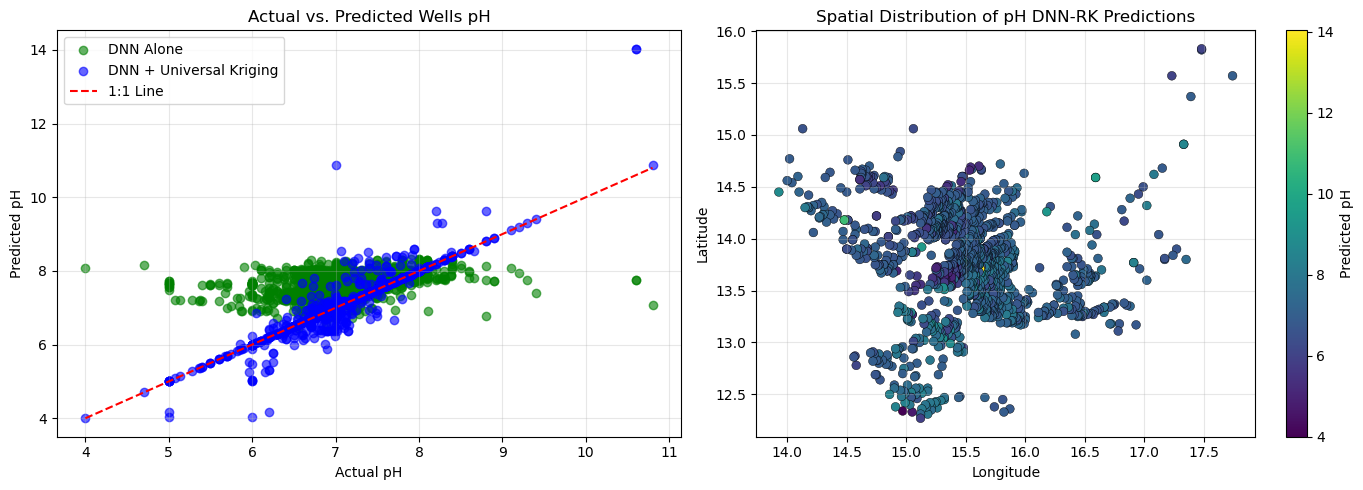

In [120]:
####### Spatial Visualizations
plt.figure(figsize = (14, 5))

# Plot 1: Actual vs Predictions
plt.subplot(1, 2, 1)
plt.scatter(y1, dnn_only_preds, alpha=0.6, label = 'DNN Alone', color = 'green')
plt.scatter(y1, dnn_rk_preds, alpha = 0.6, label = 'DNN + Universal Kriging', color = 'blue')
plt.plot([y1.min(), y1.max()], [y1.min(), y1
    .max()], 'r--', label = '1:1 Line')
plt.xlabel('Actual pH')
plt.ylabel('Predicted pH')
plt.title('Actual vs. Predicted Wells pH')
plt.legend()
plt.grid(True, alpha = 0.3)

# Plot 2: Spatial Distribution of Predictions
plt.subplot(1, 2, 2)
sc = plt.scatter(x, y_spatial, c = dnn_rk_preds, cmap='viridis', s=40, edgecolors = 'k', linewidths = 0.3)
plt.colorbar(sc, label='Predicted pH')
plt.title('Spatial Distribution of pH DNN-RK Predictions')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, alpha = 0.3)

plt.tight_layout()
plt.show()

In [52]:
                    ################# UPDATING THE DNN WITH COVARIATES TEMPERATURE AND DEPTH #####################

In [121]:
# 1. Target preparation
# covs = p
# Temp, Depth
temp = p[:,0]
depth = p[:,1]
# The Target y now depends on (x, y) AND temperature 
y_with_covs = trend + temp + residuals_true

In [122]:
# 2. Preparing Multi-Feature Input for the DNN
# Each sample now has 3 features: coords (x, y) and temperature]
X_train_multi = np.column_stack((coords, temp))

In [123]:
# 3 .Converting to Tensors
X_train_tensor = torch.tensor(X_train_multi, dtype = torch.float32)
y_train_tensor = torch.tensor(y_with_covs, dtype = torch.float32).view(-1, 1)

In [124]:
# 4. Updating the DNN Architecture (Input size is now 3)
model_cov = nn.Sequential(
    nn.Linear(3, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
optimizer = optim.RMSprop(model.parameters(), lr = 0.003)
criterion = nn.MSELoss()

In [125]:
# 5. Training the model
for epoch in range(500):
    optimizer.zero_grad()
    pred = model(X_train)
    loss = criterion(pred, y_train)
    loss.backward()
    optimizer.step()

In [126]:
# 6. Getting the DNN Trend predictions for the whole grid
full_grid_coords = np.column_stack((X.ravel(), Y.ravel()))
with torch.no_grad():
    dnn_trend = model(torch.tensor(full_grid_coords, dtype=torch.float32)).numpy().reshape(50, 50)

In [127]:
# 7. Kriging the Residuals
# 1. Calculate residuals at sample locations
with torch.no_grad():
    sample_preds = model(X_train).numpy().flatten()
residuals = y_with_covs - sample_preds

In [128]:
# 8. Fitting the Kriging model to the residuals
UK = UniversalKriging(
    coords[:, 0], 
    coords[:, 1], 
    residuals,
    variogram_model = 'gaussian',
    verbose = False,
    enable_plotting = False
)

In [129]:
# 3. Interpolating the residuals across the full grid
z_res, ss_res = UK.execute('grid', x, y)

In [130]:
############## Comparison between the standalone DNN and the hybrid model #############

In [131]:
# 1. DNN Only Prediction (at original sample locations)
with torch.no_grad():
    dnn_only_preds = model(X_train).numpy().flatten()
dnn_rmse = np.sqrt(mean_squared_error(sample_z, dnn_only_preds))

In [132]:
# 2. DNN + Kriging Prediction (at original sample locations)
# Note: We extract the kriged residuals at the exact sample coordinates
z_res_samples, _ = UK.execute('points', coords[:, 0], coords[:, 1])
dnn_rk_preds = dnn_only_preds + z_res_samples
rk_rmse = np.sqrt(mean_squared_error(y_with_covs, dnn_rk_preds))

In [133]:
print(f"Standalone DNN RMSE: {dnn_rmse:.2f}")
print(f"Regression Kriging (DNN+RK) RMSE: {rk_rmse:.2f}")
print(f"Error Reduction: {((dnn_rmse - rk_rmse) / dnn_rmse) * 100:.2f}%")

Standalone DNN RMSE: 6.36
Regression Kriging (DNN+RK) RMSE: 0.33
Error Reduction: 94.87%


In [134]:
# R-squared
dnn_rsq = r2_score(y_with_covs, dnn_only_preds)
rk_rsq = r2_score(y_with_covs, dnn_rk_preds)

In [136]:
print(f"Standalone DNN Rsq: {dnn_rsq:.2f}")
print(f"Regression Kriging (DNN+RK) Rsq: {rk_rsq:.4f}")
print(f"Error Reduction: {((dnn_rsq - rk_rsq) / dnn_rsq) * 100:.2f}%")

Standalone DNN Rsq: -38.53
Regression Kriging (DNN+RK) Rsq: 0.8985
Error Reduction: 102.33%


In [137]:
# MAE
dnn_mae = mean_absolute_error(y_with_covs, dnn_only_preds)
rk_mae = mean_absolute_error(y_with_covs, dnn_rk_preds)

In [138]:
print(f"Standalone DNN MAE: {dnn_mae:.2f}")
print(f"Regression Kriging (DNN+RK) MAE: {rk_mae:.2f}")
print(f"Error Reduction: {((dnn_mae - rk_mae) / dnn_mae) * 100:.2f}%")

Standalone DNN MAE: 6.35
Regression Kriging (DNN+RK) MAE: 0.10
Error Reduction: 98.45%


In [71]:
############# Variogram plots ##########

In [140]:
# a. Creating the Variogram Object ---
# n_lags: number of distance 'bins' to group point pairs
# maxlag: maximum distance to consider (usually 50% of the max distance in data)
V = skg.Variogram(coords, residuals, n_lags = 15, model = 'gaussian', normalize = False)

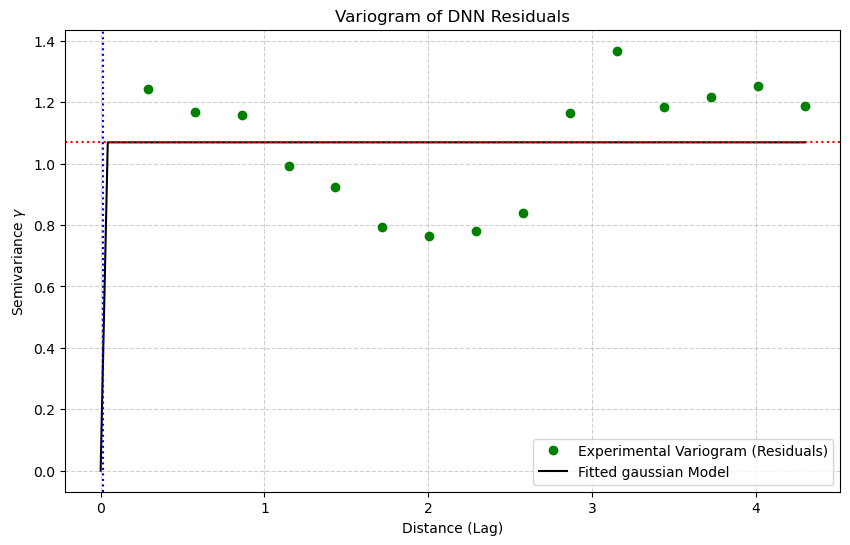

In [141]:
# b. Plotting the Experimental Variogram ---
plt.figure(figsize = (10, 6))

# Plot the experimental points (the dots)
plt.plot(V.bins, V.experimental, 'og', label = 'Experimental Variogram (Residuals)')

# Plot the fitted model (the line)
x_model = np.linspace(0, np.max(V.bins), 100)
y_model = V.fitted_model(x_model)
plt.plot(x_model, y_model, '-k', label = f'Fitted {V.model.__name__} Model')

# Formatting
plt.xlabel('Distance (Lag)')
plt.ylabel('Semivariance $\gamma$')
plt.title('Variogram of DNN Residuals')
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.6)

# Adding annotations for Kriging parameters
plt.axhline(y = V.parameters[1] + V.parameters[2], color = 'r', linestyle = ':', label = 'Sill')
plt.axvline(x = V.parameters[0], color = 'b', linestyle = ':', label = 'Range')

In [142]:
# Print the Geostatistical parameters
print(f"Range (Distance where correlation stops): {V.parameters[0]:.2f}")
print(f"Sill (Total Variance): {V.parameters[1] + V.parameters[2]:.2f}")
print(f"Nugget (Measurement Error/Micro-scale variation): {V.parameters[2]:.2f}")

Range (Distance where correlation stops): 0.01
Sill (Total Variance): 1.07
Nugget (Measurement Error/Micro-scale variation): 0.00


In [ ]:
####################################################################################